<a href="https://colab.research.google.com/github/kimve1969/PINN/blob/main/rosatom/%5BDEMO%5DBranchStress.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Анализ максимальных напряжений в отводе трубопровода

https://app.repeat.vision/docs/howto/ml_approximation/branch_stress/index.html


In [1]:
!ls -l

total 7120
-rw-r--r-- 1 jupyter jupyter    3987 Oct 24 16:46 [DEMO]2DheatModel.onnx
-rw-r--r-- 1 jupyter jupyter   34806 Oct 24 16:46 [DEMO]2DheatPINN.ipynb
-rw-r--r-- 1 jupyter jupyter 1193246 Oct 29 15:48 [DEMO]BranchStress.ipynb
-rw-r--r-- 1 jupyter jupyter 4256833 Oct 24 16:46 [DEMO]StressModel.onnx
-rw-r--r-- 1 jupyter jupyter  294828 Oct 24 16:46 branch_data.csv
-rw-r--r-- 1 jupyter jupyter    3533 Oct 24 16:46 heat_transfer_data.csv
-rw-r--r-- 1 jupyter jupyter     773 Oct 24 16:46 ml_heat_transfer.onnx
-rw-r--r-- 1 jupyter jupyter     173 Oct 24 16:46 requirements.txt
-rw-r--r-- 1 jupyter jupyter    6948 Oct 24 16:46 simple_ml_heat_transfer.ipynb
-rw-r--r-- 1 jupyter jupyter 1493976 Oct 24 16:46 stress_branch.csv


В данном ноутбуке представлен код для создания модели нейронной сети с использованием PyTorch. Решается задача предсказания максимальных напряжений, возникающих в отводе куста газовых скважин, при известных параметрах системы.

Код подготовлен компанией [АО «ИТЦ «ДЖЭТ»](https://get-sim.ru) для демонстрации интеграции возможностей импорта моделей машинного обучения на [платформу REPEAT VISION](https://app.repeat.vision) для выполнения инженерных расчётов. Для более полного ознакомления с возможностями платформы рекомендуется ознакомиться с документацией [сайте](https://app.repeat.vision/docs/).

### Описание задачи


Инженерная система газовых скважин представляет собой сеть трубопроводов и отводов, по которым транспортируется добываемый газ с высокими скоростями и давлением. Со временем на внутренней поверхности труб под действием потока абразивных частиц начинается эрозия металла, что ведёт к уменьшению толщины стенки в наиболее нагруженных участках.

Целью является разработка и обучение математической модели, способной по совокупности параметров предсказывать величину внутренних напряжений зоны, подверженной эрозионному износу. В результате использования модели оператор получит оценки напряжения, что позволит своевременно проводить ремонт или замену участков труб, минимизируя простой оборудования и риск аварий.

### Используемые библиотеки

В данном примере используется множество библиотек для анализа данных и машинного обучения. Их можно разделить на несколько категорий:

- Библиотеки для работы с данными:
    - **NumPy** - фундаментальная библиотека для научных вычислений, работы с многомерными массивами и матрицами.
    - **Pandas** - библиотека для обработки и анализа табличных данных.
- Библиотеки для визуализации:
    - **Matplotlib** и **Seaborn** - библиотеки для создания статистических графиков.
    - **Plotly** - библиотека для создания интерактивных визуализаций.
- Библиотеки для машинного обучения:
    - **PyTorch** - фреймворк для создания и обучения нейронных сетей. Включает модули с основными структурными компонентами (**torch.nn**), функциями (**torch.nn.functional**), инструментами оптимизации (**torch.optim**) и другие инструменты (**torch.utils.data**).
- Библиотеки для оценки качества модели:
    - **SciKit-Learn** - библиотека для классического машинного обучения.

> Для работы с GPU необходимо установить версию PyTorch, совместимую с вашей версией CUDA. Рекомендуется посетить официальный сайт PyTorch для получения инструкций по установке.

In [2]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import plotly.graph_objects as go

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_squared_error,
                             mean_absolute_error,
                             mean_absolute_percentage_error,
                             r2_score)

from tqdm.notebook import tqdm
from typing import Tuple, List, Dict, Union

Установка фиксированного seed для воспроизводимости результатов

In [3]:
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

Определение устройства для вычислений (GPU или CPU)

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


### Построение 3D модели отвода

График ниже представляет собой 3D визуализацию распределения напряжений в отводе трубопровода. Он показывает, как напряжения распределяются по различным координатам в конструкции. Тёплые оттенки указывают на высокие значения напряжений, а более холодные – на низкие.

In [5]:
def branch_plot(df: pd.DataFrame) -> go.Figure:
    """
    Создает 3D визуализацию распределения напряжений.

    Параметры:
        df: pd.DataFrame
            DataFrame с данными о координатах и напряжениях

    Возвращает:
        go.Figure: Объект графика Plotly
    """
    marker_config = dict(
        size=3,
        color=df['Stress'],
        colorscale='Jet',
        opacity=0.8,
        colorbar=dict(title="Напряжение (МПа)")
    )

    hover_template = (
        '<b>Узел</b>: %{customdata}<br>'
        '<b>X</b>: %{x:.2f} мм<br>'
        '<b>Y</b>: %{y:.2f} мм<br>'
        '<b>Z</b>: %{z:.2f} мм<br>'
        '<b>Напряжение</b>: %{marker.color:.2f} МПа'
    )

    fig = go.Figure(
        data=[
            go.Scatter3d(
                x=df['X'],
                y=df['Y'],
                z=df['Z'],
                mode='markers',
                marker=marker_config,
                hovertemplate=hover_template,
                customdata=df['Node']
            )
        ]
    )

    scene_config = dict(
        xaxis_title='X (мм)',
        yaxis_title='Y (мм)',
        zaxis_title='Z (мм)',
        aspectmode='data',
        camera=dict(
            eye=dict(x=0, y=0, z=2.5),
            center=dict(x=0, y=0, z=0),
            up=dict(x=0, y=1, z=0)
        )
    )

    margin_config = dict(l=0, r=0, b=0, t=30)

    fig.update_layout(
        title='Распределение напряжений',
        scene=scene_config,
        margin=margin_config
    )

    return fig

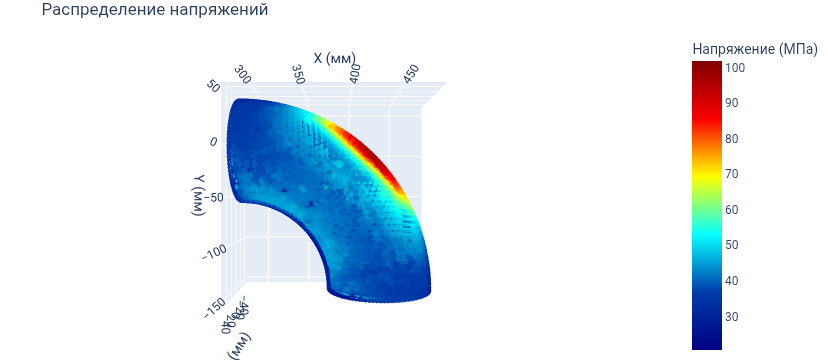

In [6]:
file_path = 'stress_branch.csv'
#df = pd.read_csv(file_path)
df = pd.read_csv('https://raw.githubusercontent.com/kimve1969/PINN/refs/heads/main/rosatom/stress_branch.csv')
fig = branch_plot(df)
fig.show()

### Данные для обучения

Набор данных представляет собой таблицу с информацией о параметрах отвода трубопровода и максимальном напряжении.

Рассмотрим основные характеристики:
- Входные параметры:
    - Давление (pressure), меняется в диапазоне: 6.0 - 8.5 МПа.
    - Температура газа (gas_temperature), меняется в диапазоне: 7.0 - 20.0 K.
    - Температура окружающей среды (ambient_temperature), меняется в диапазоне: -55.0 - 40.0 K.
    - Минимальная толщина стенки (wall_thickness_min), меняется в диапазоне: 4.90 - 6.45 мм.
- Целевая переменная:
    - Максимальное напряжение по Мизесу в конструкции (stress_max), меняется в диапазоне: 45.31 - 140.40 МПа.

In [7]:
#df = pd.read_csv('branch_data.csv')
df = pd.read_csv('https://raw.githubusercontent.com/kimve1969/PINN/refs/heads/main/rosatom/branch_data.csv')
df.describe()

,pressure,gas_temp,ambient_temp,wall_thickness,stress_max
count,6117.000000,6117.000000,6117.000000,6117.000000,6117.000000
mean,7.247180,12.969103,-7.515122,0.005678,82.533583
std,0.854169,4.939119,30.311846,0.000460,20.322778
min,6.000000,7.000000,-55.000000,0.004900,45.310563
25%,6.500000,7.000000,-45.000000,0.005300,67.980245
50%,7.000000,10.000000,-15.000000,0.005700,78.048785
75%,8.000000,15.000000,10.000000,0.006100,97.033322
max,8.500000,20.000000,40.000000,0.006450,140.399871


In [8]:
features = ['pressure', 'gas_temp', 'ambient_temp', 'wall_thickness']
target = 'stress_max'

df[features + [target]].head()

,pressure,gas_temp,ambient_temp,wall_thickness,stress_max
0,6.0,7,-55,0.00645,67.563908
1,6.0,7,-45,0.00645,56.768882
2,6.0,7,-20,0.00645,50.355252
3,6.0,7,-15,0.00645,54.834753
4,6.0,7,5,0.00645,72.591523


#### Класс StressDataset

Класс `StressDataset` представляет исходный набор данных в формат, удобный для работы с PyTorch. Класс наследуется от базового класса `torch.utils.data.Dataset`.

Внутри класса входные данные преобразуются в тензоры PyTorch, целевые значения преобразуются в тензор с формой [1, 1], все данные перемещаются на указанное устройство (CPU/GPU) при вызове их из контейнера данных, каждый признак обрабатывается как отдельный тензор (это будет необходимо для дальнейшего импорта модели в REPEAT).

In [9]:
class StressDataset(Dataset):
    """
    Класс датасета для обучения модели.
    """
    def __init__(
        self,
        X: np.ndarray,
        y: np.ndarray,
        device: torch.device = torch.device('cpu')
    ) -> None:
        """
        Инициализация набора данных.

        Параметры:
            X: np.ndarray
                Массив входных признаков
            y: np.ndarray
                Массив целевых значений
            device: torch.device
                Устройство для вычислений
        """
        super().__init__()
        self.device = device
        self.X = X
        self.y = torch.FloatTensor(y, device=self.device).reshape(-1, 1)

    def __len__(self) -> int:
        """
        Методы получения количества элементов.

        Возвращает:
            int: Количество элементов
        """
        return len(self.X)

    def __getitem__(self, idx: int) -> Tuple[Tuple[torch.Tensor, ...], torch.Tensor]:
        """
        Возвращает пару (признаки, целевое значение) для заданного индекса.

        Параметры:
            idx: int
                Индекс образца

        Возвращает:
            Tuple[Tuple[torch.Tensor, ...], torch.Tensor]:
                Кортеж из кортежа признаков и целевого значения
        """
        return (
            tuple(torch.Tensor([feature], device=self.device)
                  for feature in self.X[idx]),
            self.y[idx]
        )

In [10]:
X = df[features].values
y = df[target].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

train_dataset = StressDataset(X_train, y_train, device)
test_dataset = StressDataset(X_test, y_test, device)

batch_size = 64
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

### Нейронная сеть

Класс `StressNet` нейронной сети для предсказания максимального напряжения. Класс наследуется от базового класс `nn.Module`. Нейронная сеть представляет собой трехслойный MLP, с одинаковым размером скрытых скрытых слоев, встроенной нормализация входных данных, `LayerNorm` после каждого полносвязного слоя и `Dropout` для регуляризации.

In [11]:
class StressNet(nn.Module):
    """
    Нейронная сеть.
    """
    def __init__(
        self,
        input_size: int = 4,
        hidden_size: int = 32,
        mean: torch.Tensor = torch.zeros(4),
        std: torch.Tensor = torch.ones(4),
        dropout_rate: float = 0.2
    ) -> None:
        """
        Инициализация модели.

        Параметры:
            input_size: int
                Размер входного слоя
            hidden_size: int
                Размер скрытых слоев
            mean: torch.Tensor
                Средние значения для нормализации
            std: torch.Tensor
                Стандартные отклонения для нормализации
            dropout_rate: float
                Вероятность отключения нейронов
        """
        super().__init__()

        self.fc1 = nn.Linear(input_size, hidden_size)
        self.norm1 = nn.LayerNorm(hidden_size)
        self.fc2 = nn.Linear(hidden_size, hidden_size)
        self.norm2 = nn.LayerNorm(hidden_size)
        self.fc3 = nn.Linear(hidden_size, hidden_size)
        self.norm3 = nn.LayerNorm(hidden_size)
        self.out = nn.Linear(hidden_size, 1)

        self.act = nn.ReLU()
        self.dropout = nn.Dropout(dropout_rate)

        self.mean = mean
        self.std = std

        self.apply(self._init_weights)

    def _init_weights(self, module: nn.Module) -> None:
        """
        Инициализация весов слоев.

        Параметры:
            module: nn.Module
                Модуль для инициализации весов
        """
        if isinstance(module, nn.Linear):
            nn.init.kaiming_uniform_(
                module.weight,
                nonlinearity='linear'
            )
            nn.init.zeros_(module.bias)

    def forward(
        self,
        pressure: torch.Tensor,
        gas_temp: torch.Tensor,
        ambient_temp: torch.Tensor,
        wall_thickness: torch.Tensor
    ) -> torch.Tensor:
        """
        Прямой проход через сеть.

        Параметры:
            pressure: torch.Tensor
                Давление
            gas_temp: torch.Tensor
                Температура газа
            ambient_temp: torch.Tensor
                Температура окружения
            wall_thickness: torch.Tensor
                Толщина стенки

        Возвращает:
            torch.Tensor: Предсказанное значение максимального напряжения
        """
        batch_size = pressure.shape[0]

        x = torch.cat([
            pressure.view(batch_size, -1),
            gas_temp.view(batch_size, -1),
            ambient_temp.view(batch_size, -1),
            wall_thickness.view(batch_size, -1)
        ], dim=1)

        x = (x - self.mean) / self.std

        x = self.fc1(x)
        x = self.norm1(x)
        x = self.act(x)
        x = self.dropout(x)

        x = self.fc2(x)
        x = self.norm2(x)
        x = self.act(x)
        x = self.dropout(x)

        x = self.fc3(x)
        x = self.norm3(x)
        x = self.act(x)
        x = self.dropout(x)

        return self.out(x)

### Функция обучения модели

Функция `train_model` предназначена для обучения нейронной сети с использованием метода градиентного спуска. Вот основные компоненты и этапы работы функции:
- **Подготовка**:
    - Перенос модели на указанное устройство.
    - Инициализация списков для отслеживания потерь.
    - Настройка ранней остановки (early stopping).
- **Цикл обучения**:
    - Обучение на тренировочных данных.
    - Валидация на проверочных данных.
    - Отслеживание лучшей модели.
    - Проверка условий ранней остановки.
- **Мониторинг**:
    - Отслеживание значения функции потерь.
    - Сохранение лучшей модели.
    - Вывод прогресса обучения.

In [12]:
def train_model(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    epochs: int,
    device: torch.device = torch.device('cpu'),
    patience: int = 20
) -> Tuple[nn.Module, List[float], List[float]]:
    """
    Обучает модель нейронной сети.

    Параметры:
        model: nn.Module
            Модель нейронной сети для обучения
        train_loader: DataLoader
            Загрузчик данных для обучающей выборки
        val_loader: DataLoader
            Загрузчик данных для валидационной выборки
        criterion: nn.Module
            Функция потерь
        optimizer: optim.Optimizer
            Оптимизатор для обновления весов
        epochs: int
            Количество эпох обучения
        device: torch.device
            Устройство для вычислений (CPU/GPU)
        patience: int
            Количество проведенных эпох без улучшения, достаточное для ранней остановки обучения

    Возвращает:
        Tuple[nn.Module, List[float], List[float]]: Обученная модель,
            список потерь на обучающей выборке, список потерь на валидационной выборке
    """
    model.to(device)

    train_losses = []
    val_losses = []

    best_val_loss = float('inf')
    no_improvement = 0
    best_model_state = None

    for epoch in tqdm(range(epochs), desc='Training'):
        model.train()
        train_loss = 0.0

        for inputs, targets in train_loader:
            optimizer.zero_grad()

            outputs = model(*inputs)
            loss = criterion(outputs, targets)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * targets.size(0)

        train_loss = train_loss / len(train_loader.dataset)
        train_losses.append(train_loss)

        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for inputs, targets in val_loader:
                outputs = model(*inputs)
                loss = criterion(outputs, targets)

                val_loss += loss.item() * targets.size(0)

        val_loss = val_loss / len(val_loader.dataset)
        val_losses.append(val_loss)

        if epoch % 10 == 0:
            print(
                f'Epoch {epoch+1}/{epochs}, '
                f'Train Loss: {train_loss:.6f}, '
                f'Val Loss: {val_loss:.6f}'
            )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            no_improvement = 0
            best_model_state = model.state_dict().copy()
        else:
            no_improvement += 1
            if no_improvement >= patience:
                print(f'Early stopping at epoch {epoch+1}')
                model.load_state_dict(best_model_state)
                break

    return model, train_losses, val_losses

### Функции оценка модели

Функция `evaluate_model` предназначена для оценки производительности обученной нейронной сети на тестовом наборе данных. Она выполняет следующие действия:

1. **Подготовка модели**:
   - Переводит модель в режим оценки (`model.eval()`).
   - Отключает вычисление градиентов для оптимизации памяти.

2. **Обработка данных**:
   - Проходит по всем батчам в DataLoader.
   - Получает предсказания модели.
   - Собирает реальные значения и предсказания в списки.

3. **Расчет метрик**:
   - MSE (Mean Squared Error) - средняя квадратичная ошибка.
   - RMSE (Root Mean Squared Error) - корень из средней квадратичной ошибки.
   - MAPE (Mean Absolute Percentage Error) - средняя абсолютная процентная ошибка.
   - MAE (Mean Absolute Error) - средняя абсолютная ошибка.
   - R² (R-squared) - коэффициент детерминации.

In [13]:
def evaluate_model(
    model: nn.Module,
    data_loader: DataLoader,
    criterion: nn.Module,
    device: torch.device = torch.device('cpu')
) -> Dict[str, Union[float, np.ndarray]]:
    """
    Оценивает производительность модели на заданном наборе данных.

    Параметры:
        model: nn.Module
            Модель PyTorch для оценки
        data_loader: DataLoader
            DataLoader с данными для оценки
        criterion: nn.Module
            Функция потерь
        device: torch.device
            Устройство для вычислений

    Возвращает:
        Dict[str, Union[float, np.ndarray]]: Словарь с метриками оценки
        и результатами предсказаний
    """
    model.to(device)
    model.eval()

    all_targets = []
    all_predictions = []
    total_loss = 0.0

    with torch.no_grad():
        for inputs, targets in data_loader:
            outputs = model(*inputs)
            loss = criterion(outputs, targets)
            total_loss += loss.item() * targets.size(0)

            all_targets.extend(targets.cpu().numpy())
            all_predictions.extend(outputs.cpu().numpy())

    all_targets = np.array(all_targets).flatten()
    all_predictions = np.array(all_predictions).flatten()

    mse = mean_squared_error(all_targets, all_predictions)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(all_targets, all_predictions)
    mae = mean_absolute_error(all_targets, all_predictions)
    r2 = r2_score(all_targets, all_predictions)

    avg_loss = total_loss / len(data_loader.dataset)

    return {
        'loss': avg_loss,
        'mse': mse,
        'rmse': rmse,
        'mape': mape,
        'mae': mae,
        'r2': r2,
        'targets': all_targets,
        'predictions': all_predictions
    }

Функция `visualize_results` предназначена для визуализации динамики изменения функции потерь на обучающей и валидационной выборках  и построения гистограммы ошибок.

In [14]:
def visualize_results(
    train_losses: List[float],
    val_losses: List[float],
    test_results: Dict[str, np.ndarray]
) -> None:
    """
    Визуализирует результаты обучения модели.

    Параметры:
        train_losses: List[float]
            Список значений функции потерь на обучающей выборке
        val_losses: List[float]
            Список значений функции потерь на валидационной выборке
        test_results: Dict[str, np.ndarray]
            Словарь с результатами тестирования модели
    """
    _, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(train_losses, label='Train Loss')
    ax1.plot(val_losses, label='Val Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True)

    errors: np.ndarray = test_results['predictions'] - test_results['targets']
    sns.histplot(errors, bins=30)
    ax2.set_xlabel('Error')
    ax2.set_ylabel('Frequency')
    ax2.grid(True)

    plt.tight_layout()
    plt.show()

Функция `export_to_onnx` предназначена для экспорта обученной PyTorch модели в формат ONNX. Функция учитывает необходимости перевода в режим `double` и учитывает имена входных и выходных параметров.

### Создание, обучение и оценка нейронной сети

Создадим нейронную сеть для предсказания максимального напряжения. Используется трехслойная полносвязная архитектура.
Для стабильного обучения проведем нормализацию входных данных - для этого статистические параметры данных передаются в модель.

In [15]:
hidden_size = 512
dropout_rate = 0.2

stats = pd.DataFrame(df[features])
mean = torch.tensor(stats.mean().values, dtype=torch.float32)
std = torch.tensor(stats.std().values,  dtype=torch.float32)

model = StressNet(
    input_size=len(features),
    mean=mean,
    std=std,
    hidden_size=hidden_size,
    dropout_rate=dropout_rate
)

criterion = nn.MSELoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)

In [16]:
model, train_losses, val_losses = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=test_loader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=500,
    device=device,
    patience=10
)

Training:   0%|          | 0/500 [00:00<?, ?it/s]

Epoch 1/500, Train Loss: 4724.293387, Val Loss: 3891.476562
Epoch 11/500, Train Loss: 111.568044, Val Loss: 91.062560
Epoch 21/500, Train Loss: 35.373128, Val Loss: 22.034382
Epoch 31/500, Train Loss: 22.457592, Val Loss: 10.349939
Epoch 41/500, Train Loss: 19.377385, Val Loss: 7.464803
Epoch 51/500, Train Loss: 17.109189, Val Loss: 6.599373
Epoch 61/500, Train Loss: 16.083626, Val Loss: 6.666201
Early stopping at epoch 69


In [17]:
test_results = evaluate_model(model, test_loader, criterion, device)

print("Test metrics:")
print(f"MSE: {test_results['loss']:.3f}")
print(f"RMSE: {test_results['rmse']:.3f}")
print(f"MAPE: {test_results['mape']*100:.3f}%")
print(f"MAE: {test_results['mae']:.3f}")
print(f"R^2: {test_results['r2']:.3f}")

Test metrics:
MSE: 6.287
RMSE: 2.507
MAPE: 1.621%
MAE: 1.250
R^2: 0.985


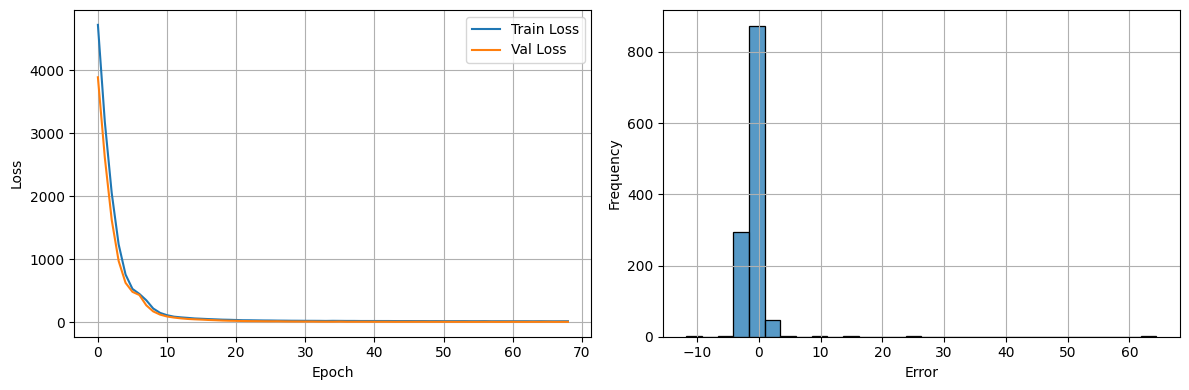

In [18]:
visualize_results(train_losses, val_losses, test_results)

### Экспорт модели в ONNX

In [19]:
def export_to_onnx(
    model: nn.Module,
    features: List[str],
    target: str,
    output_path: str = "stress_model.onnx"
) -> None:
    """
    Экспортирует PyTorch модель в формат ONNX.

    Args:
        model: nn.Module
            PyTorch модель для экспорта
        features: List[str]
            Список имен входных признаков
        target: str
            Имя целевой переменной
        output_path: str
            Путь для сохранения ONNX модели
    """
    model.eval()
    model.double()

    dummy_inputs: Dict[str, torch.Tensor] = {
        feature: torch.zeros(1, 1, dtype=torch.float64)
        for feature in features
    }

    torch.onnx.export(
        model,
        dummy_inputs,
        output_path,
        input_names=features,
        output_names=[target],
        opset_version=12,
        dynamo = False
    )

    print(f"Model exported to {output_path}.")

In [20]:
!pip install ONNX

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 47.2 MB/s  0:00:00


In [21]:
export_to_onnx(model, features, target)

/tmp/ipykernel_6125/1631747530.py:28: DeprecationWarning:

You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html



Model exported to stress_model.onnx.


In [22]:
!pip install netron

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 26.9 MB/s  0:00:00


In [23]:
import netron
from IPython.display import IFrame

onnx_model_path = "stress_model.onnx"

url = netron.start(onnx_model_path, browse=False)
IFrame(src=f"http://localhost:8080/", width=600, height=600)

In [ ]:
netron.stop()